# Early results 2 ? 400 shared puzzles, three models

I compare GPT-OSS 120B, Gemini 3.5 Flash-Lite and Claude Haiku 5.5 on **the same first 400 puzzles by collection order**, with **1,200 scored answers**. Every selected puzzle belongs to the original training set. I leave the final 200 test puzzles untouched.

I use the documented tolerant solution-move mention rule. This checkpoint is exploratory and follows inspected pilot results and a post-hoc scoring amendment. I preserve the original 100-puzzle strict figures separately. I make no API calls or collection changes here.

I fit a pooled logistic regression to estimate adjusted associations with success, and a separate XGBoost model for each LLM. My five-fold cross-validation is an early prediction check within training data, not final test accuracy. I save frozen inputs, model files, coefficients, CV predictions and three figures in `early_results_400` folders.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import redirect_stdout
import json, hashlib, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, brier_score_loss, confusion_matrix
import xgboost
from xgboost import XGBClassifier
import joblib, nbformat, requests
from IPython.display import display

# I forbid network calls in this analysis notebook.
def no_network(*args, **kwargs): raise RuntimeError('This notebook only analyzes saved answers; network access is disabled.')
requests.sessions.Session.request = no_network
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/stage_index.json').exists())
CFG=ROOT/'experiments/one_move_v1'; BASE=ROOT/'data/experiments/one_move_v1'
OUT=ROOT/'data/analysis/one_move_v1/early_results_400'; OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/'figures/one_move_v1/early_results_400'; FIG.mkdir(parents=True,exist_ok=True)
PLAN=json.loads((CFG/'early_400_plan.json').read_text()); RECIPE=json.loads((BASE/'feature_recipe.json').read_text())
assert xgboost.__version__==PLAN['xgboost_version']
MODELS={'gpt_oss':'GPT-OSS 120B','gemini':'Gemini 3.5 Flash-Lite','claude_haiku':'Claude Haiku 5.5'}
COLORS={'gpt_oss':'#2563eb','gemini':'#16a34a','claude_haiku':'#d97706'}

def sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def save(p,v):Path(p).write_text(json.dumps(v,indent=2)+'\n',encoding='utf-8')
def notebook_code_sha():
    book=nbformat.read(ROOT/'notebooks/05b_early_results_400.ipynb',as_version=4)
    return hashlib.sha256('\n\n'.join(c.source for c in book.cells if c.cell_type=='code').encode()).hexdigest()

# I protect raw answers, the source sample, PDFs and historical pilot artifacts.
protected={}
for model in MODELS:
    for fn in ['requests.jsonl','outcomes.jsonl','results.csv','audit.json','summary.json']:
        p=BASE/model/fn; protected[p.relative_to(ROOT).as_posix()]=sha(p)
for folder in ['writing','figures/one_move_v1/early','data/analysis/one_move_v1/early']:
    for p in (ROOT/folder).rglob('*'):
        if p.is_file():protected[p.relative_to(ROOT).as_posix()]=sha(p)
for fn in ['puzzles.csv','analysis_features.csv','feature_recipe.json']:
    protected[(BASE/fn).relative_to(ROOT).as_posix()]=sha(BASE/fn)
print('Offline analysis only. XGBoost version:',xgboost.__version__)


Offline analysis only. XGBoost version: 3.4.1


## 1. Freeze exactly the same 400 cases

In [2]:
prep=json.loads((BASE/'preparation.json').read_text())
assert sha(BASE/'analysis_features.csv')==prep['feature_sha256']
assert sha(BASE/'puzzles.csv')==prep['sample_sha256']
features=pd.read_csv(BASE/'analysis_features.csv',dtype={'puzzle_id':str})
selected=features.sort_values('collection_order').head(400).copy()
assert selected.collection_order.tolist()==list(range(1,401))
assert len(selected)==selected.puzzle_id.nunique()==400 and selected.split.eq('train').all()
assert not set(selected.puzzle_id)&set(features.loc[features.split.eq('test'),'puzzle_id'])
frames={}; receipts={}
for name in MODELS:
    folder=BASE/name; audit=json.loads((folder/'audit.json').read_text())
    assert audit['passed'] and audit['scoring_version']==PLAN['scoring_version']
    assert audit['results_sha256']==sha(folder/'results.csv')
    assert audit['sample_sha256']==prep['sample_sha256']
    assert audit['scoring_amendment_sha256']==sha(CFG/'scoring_amendment.json')
    result=pd.read_csv(folder/'results.csv',dtype={'puzzle_id':str})
    cols=['puzzle_id','status','success','strict_success','failure_type','answer','returned_model','trial_id','scoring_version']
    data=selected.merge(result[cols],on='puzzle_id',how='left',validate='one_to_one').sort_values('collection_order').reset_index(drop=True)
    assert len(data)==400 and data.status.eq('completed').all() and data.success.isin([0,1]).all()
    assert data.scoring_version.eq(PLAN['scoring_version']).all() and data.returned_model.nunique()==1
    data['success']=data.success.astype(int);data['strict_success']=data.strict_success.astype(int)
    frames[name]=data
    receipts[name]={'results_sha256':sha(folder/'results.csv'),'audit_sha256':sha(folder/'audit.json'),'returned_models':sorted(data.returned_model.unique())}

snapshot_path=OUT/'snapshot.json'
if not snapshot_path.exists():
    snapshot={'created_utc':datetime.now(timezone.utc).isoformat(),'plan_sha256':sha(CFG/'early_400_plan.json'),
      'scoring_amendment_sha256':sha(CFG/'scoring_amendment.json'),'sample_sha256':prep['sample_sha256'],
      'features_sha256':prep['feature_sha256'],'recipe_sha256':sha(BASE/'feature_recipe.json'),
      'code_sha256':notebook_code_sha(),'n_per_model':400,'unique_puzzles':400,'answers':1200,
      'original_test_cases_used':0,'selected_ids':selected.puzzle_id.tolist(),'source_receipts':receipts,'inputs_sha256':{}}
    for name,data in frames.items():
        data.to_csv(OUT/(name+'_inputs.csv'),index=False)
        snapshot['inputs_sha256'][name]=sha(OUT/(name+'_inputs.csv'))
    save(snapshot_path,snapshot)
else:snapshot=json.loads(snapshot_path.read_text())
assert snapshot['plan_sha256']==sha(CFG/'early_400_plan.json') and snapshot['code_sha256']==notebook_code_sha()
assert snapshot['scoring_amendment_sha256']==sha(CFG/'scoring_amendment.json')
assert snapshot['selected_ids']==selected.puzzle_id.tolist()
for name in MODELS:
    path=OUT/(name+'_inputs.csv');assert sha(path)==snapshot['inputs_sha256'][name]
    frozen=pd.read_csv(path,dtype={'puzzle_id':str})
    assert frozen.trial_id.tolist()==frames[name].trial_id.tolist()
    assert frozen.success.tolist()==frames[name].success.tolist()
    frames[name]=frozen
assert all(frames[name].puzzle_id.tolist()==selected.puzzle_id.tolist() for name in MODELS)
predictors=RECIPE['full']
tree_predictors=[{'rating_500':'puzzle_rating','legal_moves_10':'legal_moves','piece_count_10':'piece_count'}.get(k,k) for k in predictors]
labels={'rating_500':'Rating (+500 points)','legal_moves_10':'Legal moves (+10)','piece_count_10':'Pieces (+10)',
 'material_balance':'Material balance','puzzle_rating':'Puzzle rating','legal_moves':'Legal moves','piece_count':'Piece count',
 'theme_pin':'Pin theme','theme_kingsideAttack':'Kingside attack theme','theme_hangingPiece':'Hanging piece theme',
 'phase_endgame':'Endgame vs middlegame','phase_opening':'Opening vs middlegame',
 'is_gemini':'Gemini vs GPT-OSS','is_claude':'Claude vs GPT-OSS'}
def wilson(correct,n):
    p=correct/n;z=1.96;den=1+z*z/n;center=(p+z*z/(2*n))/den;half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return float(center-half),float(center+half)
accuracy=[]
for name,data in frames.items():
    correct=int(data.success.sum());lo,hi=wilson(correct,400)
    accuracy.append({'model_key':name,'Model':MODELS[name],'Correct':correct,'Puzzles':400,'LLM accuracy':correct/400,'CI low':lo,'CI high':hi})
accuracy=pd.DataFrame(accuracy);accuracy.to_csv(OUT/'accuracy.csv',index=False)
display(accuracy[['Model','Correct','Puzzles','LLM accuracy']])
print('All 400 selected puzzles are original training cases. Final 200-case test set: unused.')


,Model,Correct,Puzzles,LLM accuracy
0,GPT-OSS 120B,164,400,0.4100
1,Gemini 3.5 Flash-Lite,229,400,0.5725
2,Claude Haiku 5.5,200,400,0.5000


All 400 selected puzzles are original training cases. Final 200-case test set: unused.


## 2. Logistic regression: board characteristics and model identity

I use all 1,200 answers with 400 puzzle clusters, including the frozen numeric, theme and phase predictors. GPT-OSS is the identity reference. I report adjusted associations, not causal effects. Ordinary 95% intervals are exploratory; I make no multiple-testing-adjusted significance claims. The rating graph holds numeric board features at the selected training medians, themes absent and phase at the middlegame reference.

In [3]:
pooled=pd.concat([d.assign(is_gemini=int(name=='gemini'),is_claude=int(name=='claude_haiku'),model_key=name) for name,d in frames.items()],ignore_index=True)
terms=predictors+['is_gemini','is_claude']
X=sm.add_constant(pooled[terms].astype(float),has_constant='add');y=pooled.success.astype(int)
assert all(min(int(d.success.sum()),400-int(d.success.sum()))>=50 for d in frames.values())
assert np.linalg.matrix_rank(X.to_numpy())==X.shape[1], 'Fixed regression is rank deficient; no silent feature deletion.'
model_path=OUT/'logistic_regression.joblib'
if model_path.exists():fit=joblib.load(model_path)
else:
    with warnings.catch_warnings():
        warnings.simplefilter('error',PerfectSeparationWarning)
        fit=sm.GLM(y,X,family=sm.families.Binomial()).fit(cov_type='cluster',cov_kwds={'groups':pd.factorize(pooled.puzzle_id)[0]})
    assert fit.converged and np.isfinite(fit.params).all() and np.isfinite(fit.cov_params().to_numpy()).all()
    joblib.dump(fit,model_path)
assert fit.model.exog_names==X.columns.tolist() and fit.nobs==1200
ci=fit.conf_int()
coefs=pd.DataFrame({'term':fit.params.index,'Characteristic':[labels.get(k,k) for k in fit.params.index],
    'coefficient':fit.params.values,'Odds ratio':np.exp(fit.params.values),'CI low':np.exp(ci[0].values),'CI high':np.exp(ci[1].values)})
assert np.isfinite(coefs.select_dtypes('number').to_numpy()).all()
coefs.to_csv(OUT/'logistic_coefficients.csv',index=False)
display(coefs.loc[coefs.term.ne('const'),['Characteristic','Odds ratio','CI low','CI high']].round(3))
print('Converged regression: 1,200 answers, 400 puzzle clusters,',X.shape[1],'coefficients including intercept.')


,Characteristic,Odds ratio,CI low,CI high
1,Rating (+500 points),0.580,0.495,0.679
2,Legal moves (+10),0.957,0.789,1.161
3,Pieces (+10),1.063,0.717,1.576
4,Material balance,1.006,0.959,1.056
5,Pin theme,0.639,0.369,1.107
6,Kingside attack theme,1.722,1.059,2.801
7,Hanging piece theme,2.554,1.204,5.417
8,Endgame vs middlegame,1.455,0.924,2.292
9,Opening vs middlegame,0.924,0.505,1.690
10,Gemini vs GPT-OSS,2.063,1.563,2.724


Converged regression: 1,200 answers, 400 puzzle clusters, 12 coefficients including intercept.


## 3. XGBoost: predict whether each LLM succeeds

I fit three separate XGBoost classifiers using the same nine board features and fixed 150-tree, depth-3 specification. I perform no parameter search or early stopping. For an exploratory check, I use the same five rating-stratified folds for all three models: each fold trains on 320 puzzle IDs and predicts 80 unseen IDs. Each answer receives exactly one out-of-fold prediction. I then retain a full-400 fitted model for each LLM. These predictions concern **whether the LLM succeeds**, not which chess move to play.

The CV metrics below are not LLM solving accuracy and do not replace the final reserved test evaluation. Because this checkpoint follows inspected pilot results, I treat them as exploratory.

In [4]:
assert len(tree_predictors)==9
fold_path=OUT/'cv_folds.csv'
if not fold_path.exists():
    fold=np.full(400,-1,dtype=int)
    for k,(train_idx,valid_idx) in enumerate(StratifiedKFold(n_splits=5,shuffle=True,random_state=401).split(selected,selected.rating_stratum)):
        assert len(train_idx)==320 and len(valid_idx)==80 and not set(train_idx)&set(valid_idx)
        fold[valid_idx]=k
    pd.DataFrame({'puzzle_id':selected.puzzle_id,'fold':fold}).to_csv(fold_path,index=False)
folds=pd.read_csv(fold_path,dtype={'puzzle_id':str});assert folds.puzzle_id.tolist()==selected.puzzle_id.tolist()
assert folds.fold.value_counts().to_dict()=={k:80 for k in range(5)}
params=PLAN['xgboost_parameters'];metrics=[];importance=[];boosters={};model_receipts={}
for name,data in frames.items():
    xx=data[tree_predictors].astype(float);yy=data.success.astype(int)
    oof_path=OUT/(name+'_cv_predictions.csv')
    if not oof_path.exists():
        probability=np.full(400,np.nan);baseline=np.full(400,-1,dtype=int)
        for k in range(5):
            valid=folds.fold.eq(k).to_numpy();train=~valid
            assert not set(data.loc[train,'puzzle_id'])&set(data.loc[valid,'puzzle_id'])
            assert min(int(yy.loc[train].sum()),int(train.sum())-int(yy.loc[train].sum()))>=30
            classifier=XGBClassifier(**params)
            classifier.fit(xx.loc[train],yy.loc[train])
            probability[valid]=classifier.predict_proba(xx.loc[valid])[:,list(classifier.classes_).index(1)]
            baseline[valid]=int(yy.loc[train].mean()>=.5)
        assert np.isfinite(probability).all()
        pd.DataFrame({'puzzle_id':data.puzzle_id,'fold':folds.fold,'truth':yy,'probability':probability,
          'prediction':(probability>=.5).astype(int),'training_majority_prediction':baseline}).to_csv(oof_path,index=False)
    pred=pd.read_csv(oof_path,dtype={'puzzle_id':str})
    assert pred.puzzle_id.tolist()==data.puzzle_id.tolist() and pred.truth.tolist()==yy.tolist()
    assert pred.fold.tolist()==folds.fold.tolist()
    count=int((pred.prediction==yy).sum());lo,hi=wilson(count,400)
    metrics.append({'model_key':name,'Model':MODELS[name],'OOF cases':400,'XGBoost CV accuracy':float(accuracy_score(yy,pred.prediction)),
       'CI low':lo,'CI high':hi,'Balanced accuracy':float(balanced_accuracy_score(yy,pred.prediction)),
       'ROC AUC':float(roc_auc_score(yy,pred.probability)),'Brier score':float(brier_score_loss(yy,pred.probability)),
       'OOF majority baseline':float(accuracy_score(yy,pred.training_majority_prediction)),
       'confusion_tn_fp_fn_tp':confusion_matrix(yy,pred.prediction,labels=[0,1]).ravel().tolist()})
    path=OUT/(name+'_xgboost.ubj')
    if path.exists():
        full=XGBClassifier();full.load_model(path)
    else:
        full=XGBClassifier(**params);full.fit(xx,yy);full.save_model(path)
    assert full.get_booster().num_boosted_rounds()==150
    assert full.get_booster().feature_names==tree_predictors
    boosters[name]=full
    gain=full.feature_importances_.astype(float);assert np.isclose(gain.sum(),1)
    for feature,value in zip(tree_predictors,gain):importance.append({'model_key':name,'Model':MODELS[name],'feature':feature,'Characteristic':labels[feature],'Normalized training gain':float(value)})
    model_receipts[name]={'native_model_sha256':sha(path),'input_sha256':snapshot['inputs_sha256'][name],
      'training_ids':data.puzzle_id.tolist(),'n_train':400,'original_test_cases_used':0,'features':tree_predictors,
      'parameters':params,'cv_predictions_sha256':sha(oof_path),'cv_folds_sha256':sha(fold_path),'xgboost_version':xgboost.__version__}
    save(OUT/(name+'_xgboost_metadata.json'),model_receipts[name])
metrics=pd.DataFrame(metrics);metrics.to_csv(OUT/'xgboost_cv_metrics.csv',index=False)
importance=pd.DataFrame(importance);importance.to_csv(OUT/'xgboost_feature_importance.csv',index=False)
display(metrics[['Model','XGBoost CV accuracy','Balanced accuracy','ROC AUC','Brier score','OOF majority baseline']].round(3))
print('Saved three native XGBoost models fitted on 400 training puzzles each. No final test evaluation.')


,Model,XGBoost CV accuracy,Balanced accuracy,ROC AUC,Brier score,OOF majority baseline
0,GPT-OSS 120B,0.592,0.560,0.596,0.246,0.590
1,Gemini 3.5 Flash-Lite,0.670,0.655,0.681,0.226,0.572
2,Claude Haiku 5.5,0.568,0.568,0.599,0.252,0.445


Saved three native XGBoost models fitted on 400 training puzzles each. No final test evaluation.


## 4. Early-results figures

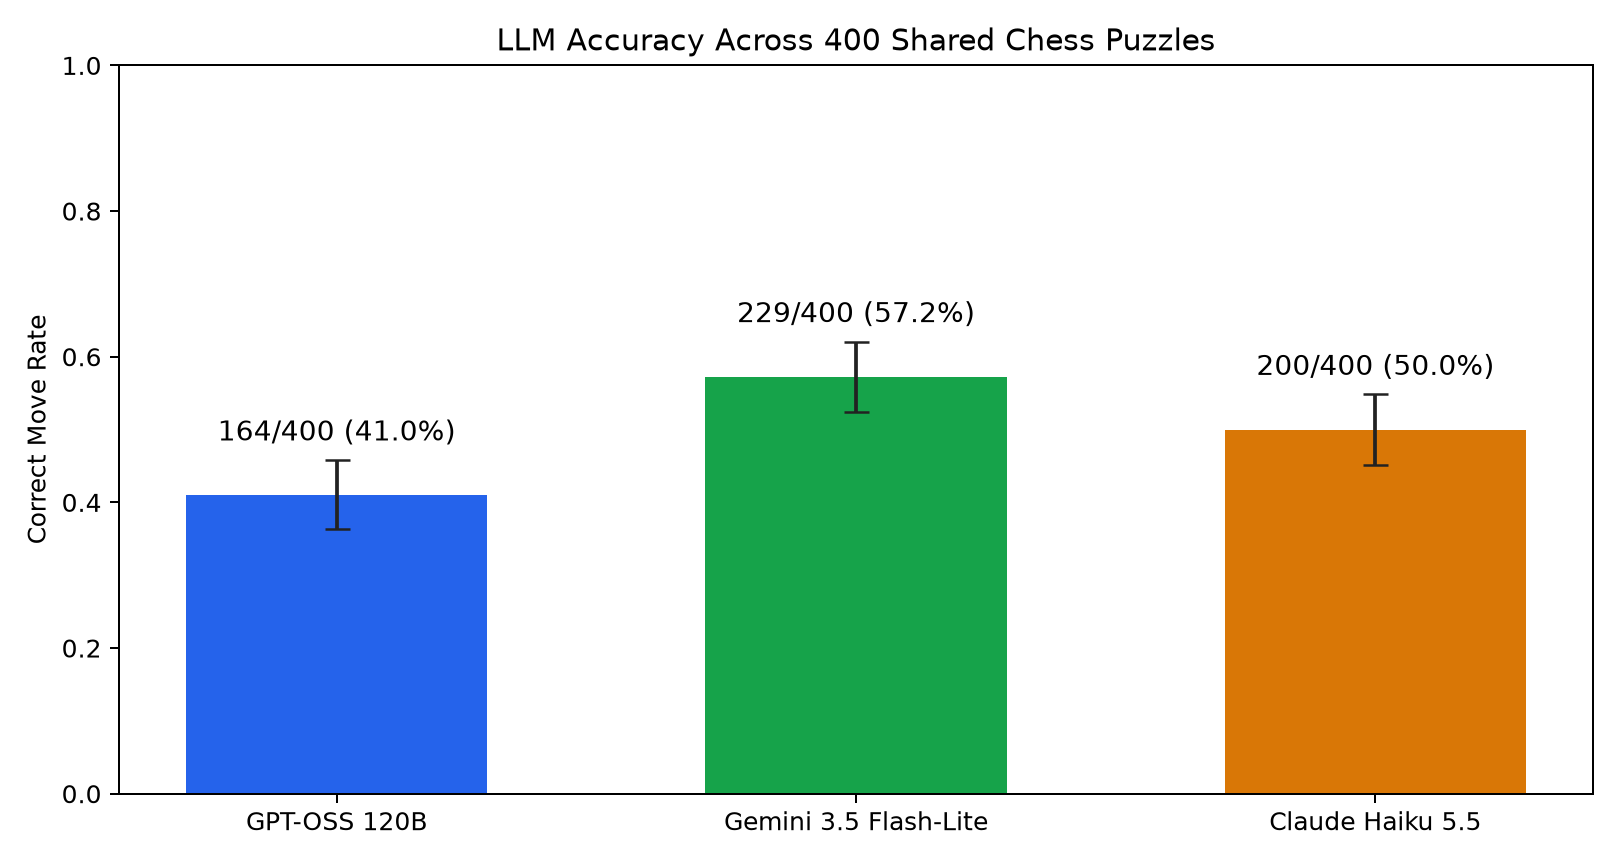

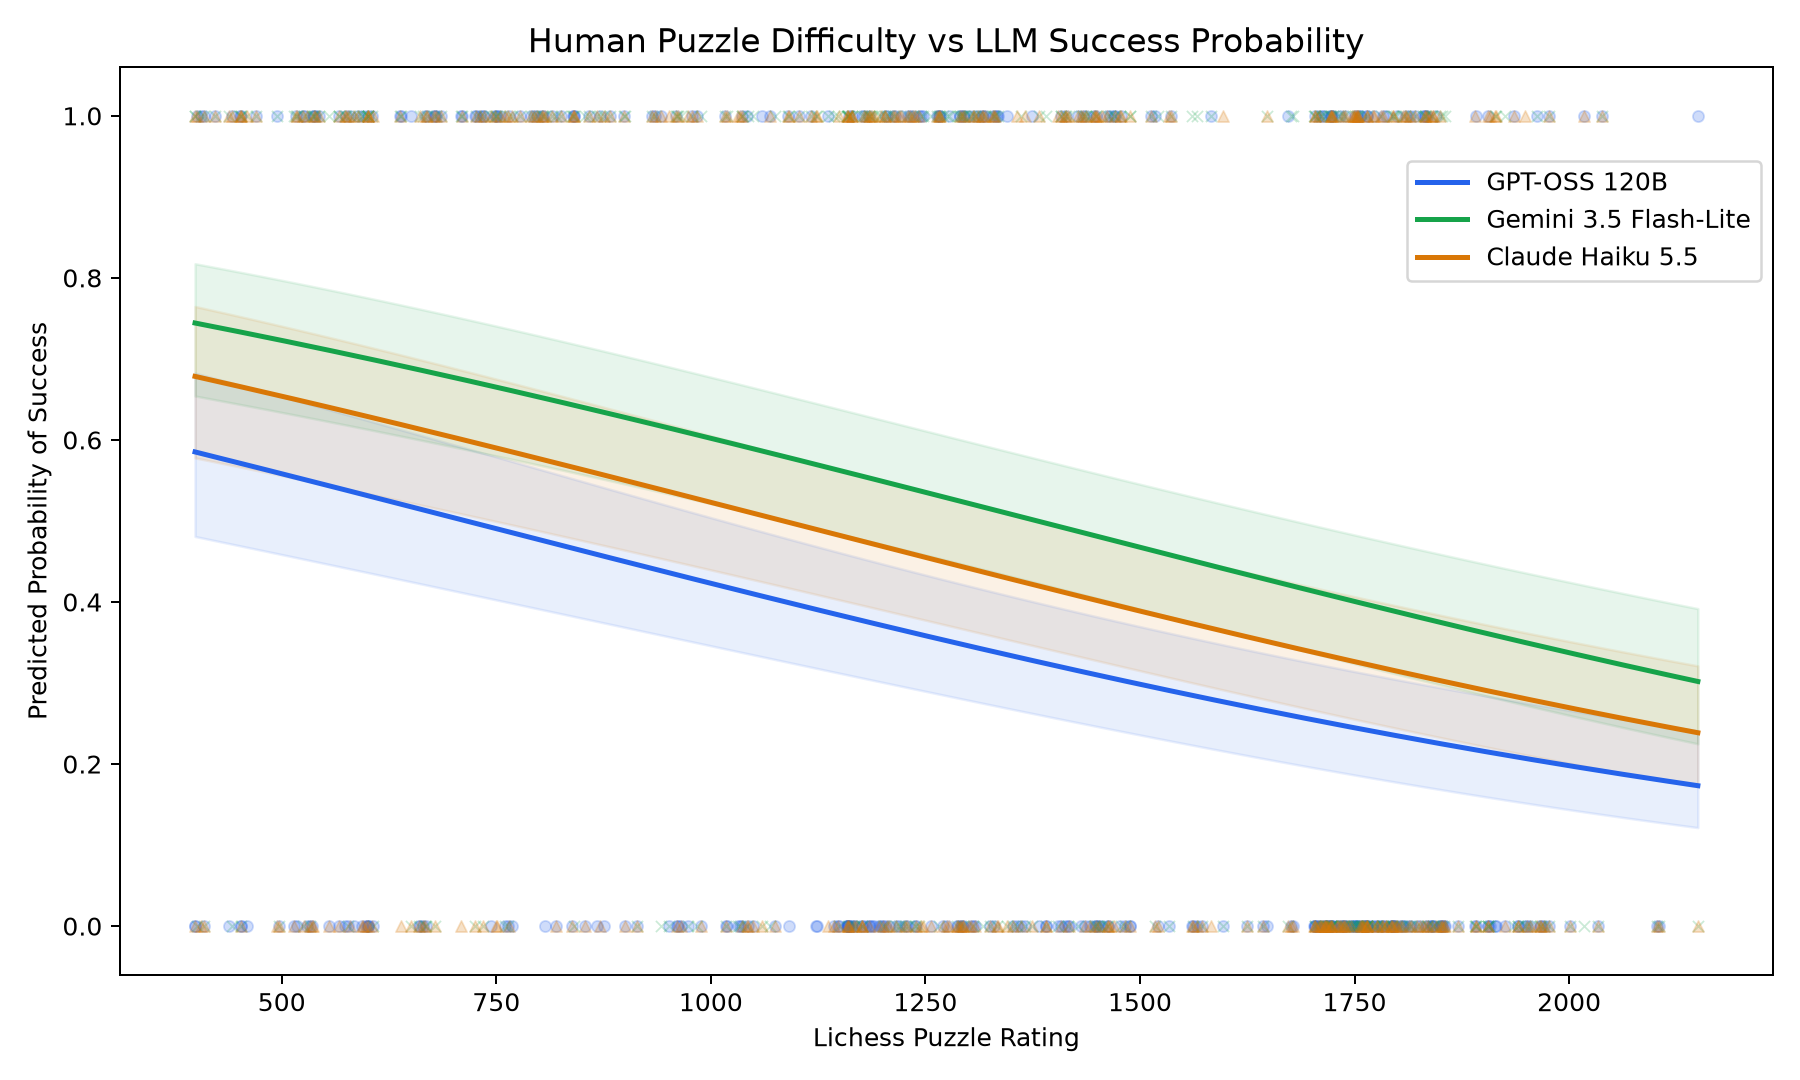

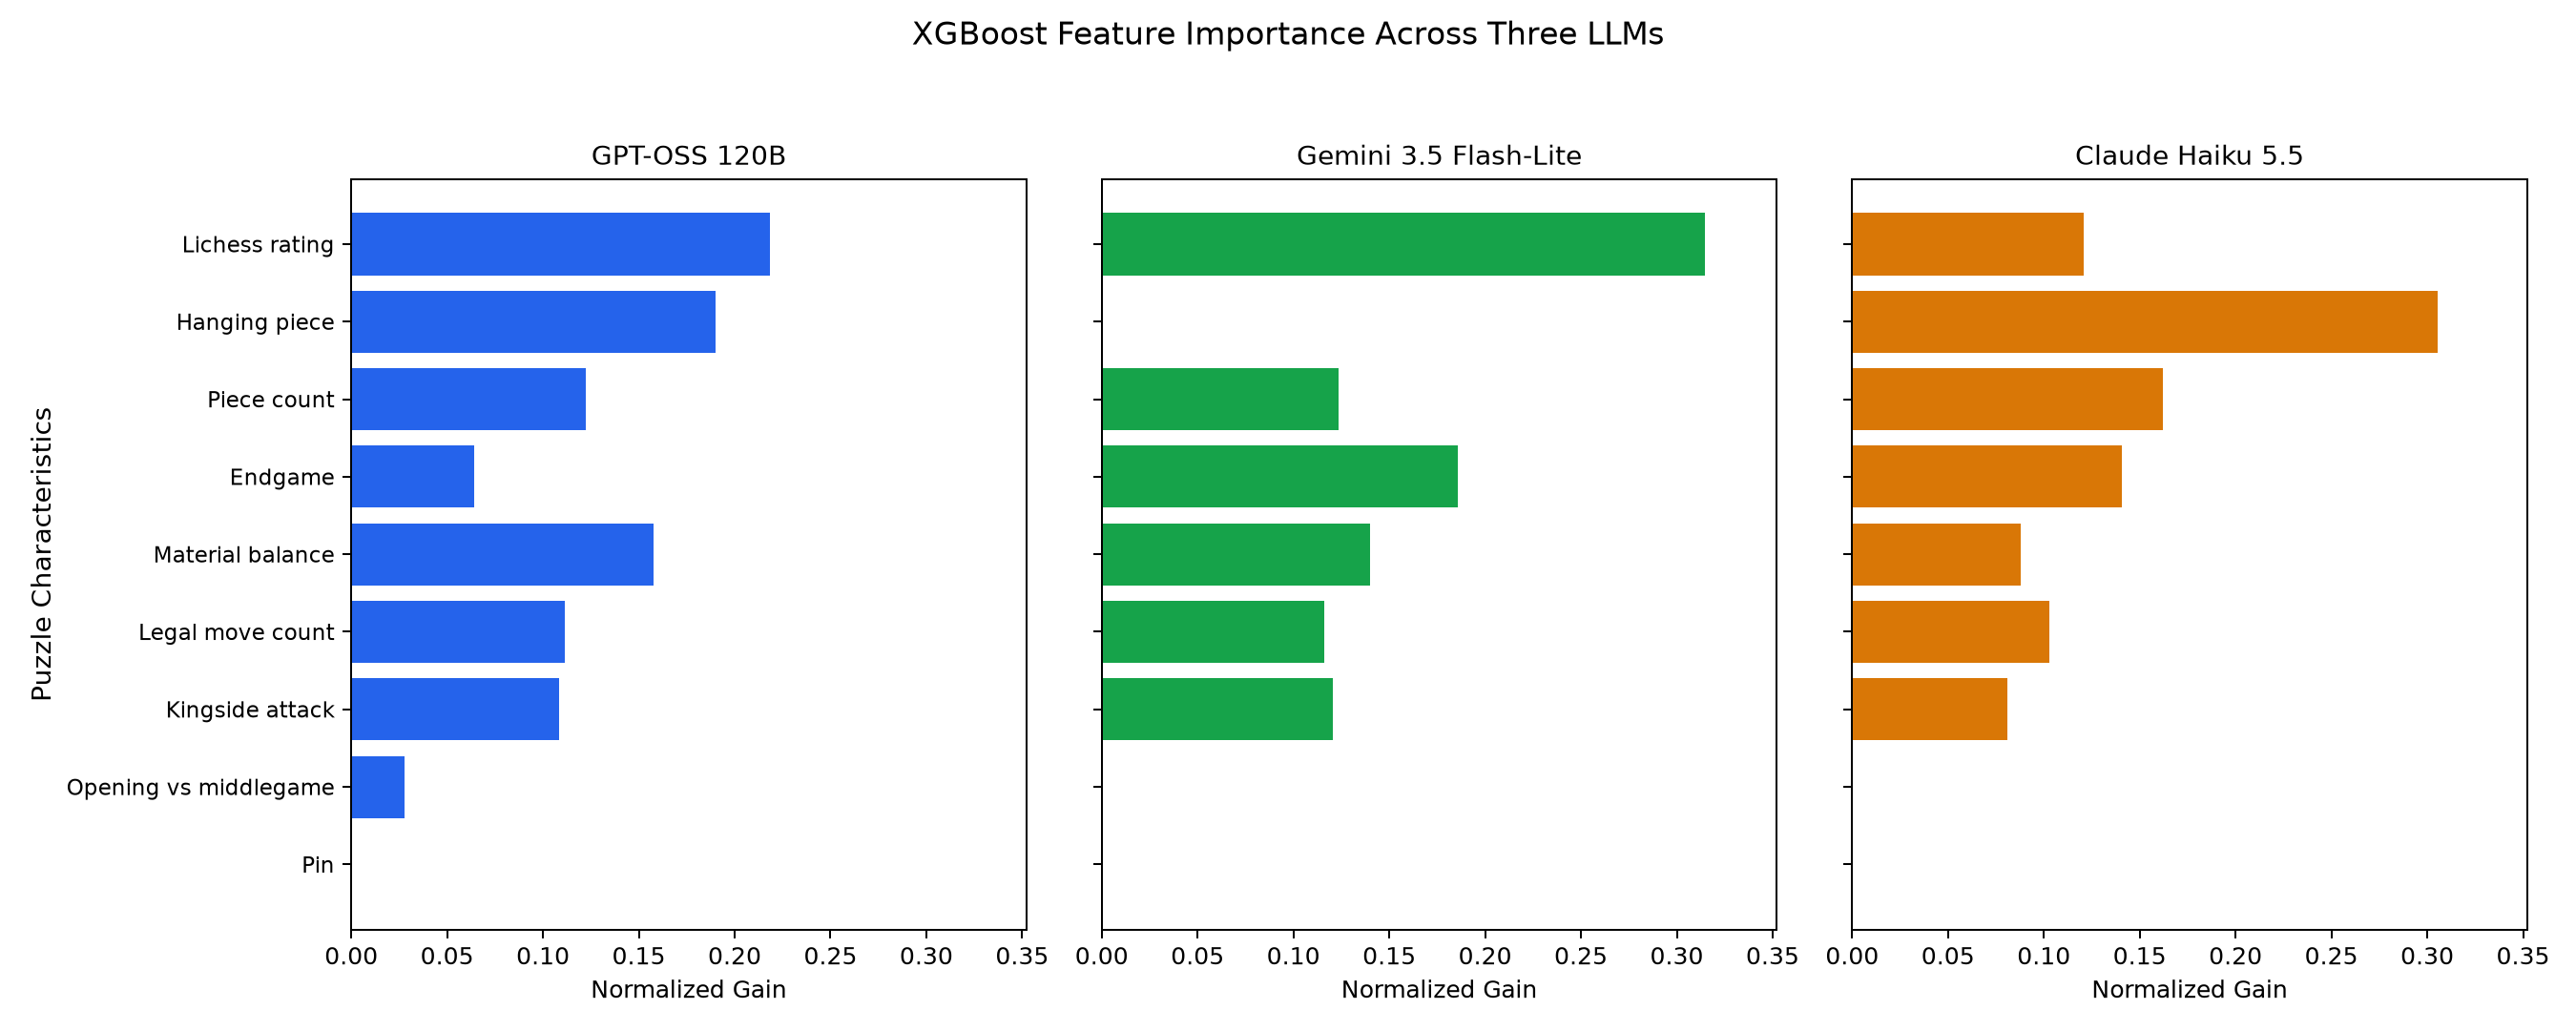

In [5]:
fig,ax=plt.subplots(figsize=(9,4.8))
for i,row in accuracy.iterrows():
    p=row['LLM accuracy'];ax.bar(i,p,width=.58,color=COLORS[row.model_key])
    ax.errorbar(i,p,yerr=[[p-row['CI low']],[row['CI high']-p]],fmt='none',color='#222222',capsize=5)
    ax.text(i,p+.075,f"{row.Correct}/400 ({p:.1%})",ha='center',fontsize=11)
ax.set(xticks=range(3),xticklabels=accuracy.Model.tolist(),ylim=(0,1),ylabel='Correct Move Rate',
       title='LLM Accuracy Across 400 Shared Chess Puzzles')
fig.tight_layout();fig.savefig(FIG/'accuracy.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(10,6))
ratings=np.linspace(selected.puzzle_rating.min(),selected.puzzle_rating.max(),200)
reference={k:0. for k in predictors}
for k in RECIPE['core']:reference[k]=float(selected[k].median())
markers={'gpt_oss':'o','gemini':'x','claude_haiku':'^'}
for name,data in frames.items():
    ax.scatter(data.puzzle_rating,data.success,color=COLORS[name],marker=markers[name],s=20,alpha=.22,linewidths=.7,zorder=3)
    grid=pd.DataFrame({k:np.full(200,v) for k,v in reference.items()})
    grid['rating_500']=(ratings-1500)/500;grid['is_gemini']=int(name=='gemini');grid['is_claude']=int(name=='claude_haiku')
    grid=sm.add_constant(grid,has_constant='add')[X.columns]
    prediction=fit.get_prediction(grid).summary_frame()
    ax.plot(ratings,prediction['mean'],color=COLORS[name],label=MODELS[name],linewidth=2)
    ax.fill_between(ratings,prediction.mean_ci_lower,prediction.mean_ci_upper,color=COLORS[name],alpha=.10)
ax.set(ylim=(-.06,1.06),xlabel='Lichess Puzzle Rating',ylabel='Predicted Probability of Success')
ax.set_title('Human Puzzle Difficulty vs LLM Success Probability',fontsize=13)
ax.legend(loc='upper right',bbox_to_anchor=(1,.91))
fig.tight_layout();fig.savefig(FIG/'logistic_regression.png',dpi=180);plt.show()

plot_labels=dict(labels, puzzle_rating='Lichess rating', theme_hangingPiece='Hanging piece',
                 phase_endgame='Endgame', legal_moves='Legal move count',
                 theme_kingsideAttack='Kingside attack', theme_pin='Pin')
order=importance.groupby('feature')['Normalized training gain'].mean().sort_values().index.tolist()
fig,axes=plt.subplots(1,3,figsize=(15,6),sharey=True)
for ax,(name,label) in zip(axes,MODELS.items()):
    data=importance.loc[importance.model_key.eq(name)].set_index('feature').loc[order]
    ax.barh(range(len(order)),data['Normalized training gain'],color=COLORS[name])
    ax.set_title(label,fontsize=11);ax.set_xlabel('Normalized Gain');ax.set_xlim(0,max(.35,float(importance['Normalized training gain'].max())*1.12))
axes[0].set_yticks(range(len(order)),[plot_labels[k] for k in order],fontsize=9)
axes[0].set_ylabel('Puzzle Characteristics',fontsize=11)
fig.suptitle('XGBoost Feature Importance Across Three LLMs',fontsize=13)
fig.tight_layout(rect=(0,0,1,.94));fig.savefig(FIG/'xgboost_feature_importance.png',dpi=180);plt.show()


## 5. Checkpoint verification

I preserve the original raw answers, original 100-puzzle figures, PDFs and final split. Model accuracy here means LLM puzzle-solving accuracy; the separate CV table measures XGBoost's prediction of LLM success. I have not used the final test set, performed parameter search or created a final three-model analysis.

In [6]:
assert all(sha(ROOT/p)==h for p,h in protected.items()), 'A protected source or historical artifact changed.'
assert all(len(d)==400 and d.split.eq('train').all() for d in frames.values())
assert len(pooled)==1200 and pooled.puzzle_id.nunique()==400
assert not set(selected.puzzle_id)&set(features.loc[features.split.eq('test'),'puzzle_id'])
status={'status':'complete','checkpoint':'early_results_400','scoring_version':PLAN['scoring_version'],
 'models':list(MODELS),'n_per_model':400,'unique_puzzles':400,'answers':1200,
 'original_test_cases_used':0,'logistic_regression_fitted':True,'logistic_puzzle_clusters':400,
 'xgboost_full_training_n':400,'xgboost_cv_folds':5,'xgboost_cv_training_per_fold':320,'xgboost_cv_validation_per_fold':80,
 'hyperparameter_search':False,'early_stopping':False,'new_api_requests':0,
 'accuracy':accuracy.to_dict('records'),'cv_metrics':metrics.to_dict('records'),
 'model_receipts':model_receipts,'figures':{p.name:sha(p) for p in FIG.glob('*.png')},
 'protected_sources_unchanged':len(protected),'plan_sha256':sha(CFG/'early_400_plan.json'),
 'snapshot_sha256':sha(snapshot_path),'python':platform.python_version(),'xgboost_version':xgboost.__version__}
save(OUT/'status.json',status)
print('Verified: same 400 IDs per model, 1,200 answers, original test set unused, zero API calls.')
print('Figures:',FIG.relative_to(ROOT))
print('Models and tables:',OUT.relative_to(ROOT))


Verified: same 400 IDs per model, 1,200 answers, original test set unused, zero API calls.
Figures: figures\one_move_v1\early_results_400
Models and tables: data\analysis\one_move_v1\early_results_400
